# NEU Steel Surface Defects | Final held-out test

**Reproducible multiclass evaluation on 360 previously unseen test images** 

In [4]:
from pathlib import Path
import os, json, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from scipy.stats import entropy
from skimage.feature import hog, local_binary_pattern
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, precision_recall_fscore_support,
    classification_report, confusion_matrix
)
from IPython.display import display
import joblib

hint = os.environ.get('NEU_PROJECT_ROOT')
roots = ([Path(hint).expanduser()] if hint else []) + [
    Path.home() / 'base' / 'NEU_Steel_Defects_CPU', Path.cwd(), *Path.cwd().parents
]
ROOT = next((p.resolve() for p in roots if (p/'outputs'/'step4_selected_pipeline.joblib').is_file()
             and (p/'outputs'/'step1_dataset_manifest.csv').is_file()), None)
if ROOT is None:
    raise FileNotFoundError('Cannot locate the Step 4 model and Step 1 manifest. Set NEU_PROJECT_ROOT.')
OUT = ROOT / 'outputs'
marker = OUT / 'step5_final_test_metrics.json'
if marker.exists():
    raise RuntimeError(
        f'Final test already evaluated: {marker}. Do not run Step 5 again to tune the model. '
        'Use the saved metrics, predictions and figures for reporting.'
    )

manifest = pd.read_csv(OUT/'step1_dataset_manifest.csv')
meta = json.loads((OUT/'step3_feature_summary.json').read_text(encoding='utf-8'))
selection = json.loads((OUT/'step4_selected_model_info.json').read_text(encoding='utf-8'))
required = {'path','split','label','sha256'}
assert required.issubset(manifest.columns), f'Missing manifest columns: {required-set(manifest.columns)}'
assert not selection['holdout_evaluated'], 'Step 4 metadata says test was already evaluated.'
assert meta['dataset'] == selection['dataset'] == 'NEU-DET'
assert meta['feature_count'] == selection['n_features']
assert meta['image_size'] == selection['feature_extraction']['image_size']

expected_sizes = [
    int(meta['feature_group_sizes'][name])
    for name in ('hog', 'lbp', 'statistics')
]

saved_sizes = [
    int(value)
    for value in selection['feature_group_sizes']
]

print("Step 3 feature sizes:", expected_sizes)
print("Step 4 feature sizes:", saved_sizes)

assert expected_sizes == saved_sizes, (
    f"Feature mismatch: {expected_sizes} vs {saved_sizes}"
)

print("Feature metadata verification: PASSED")

print('Project:', ROOT)
print('CV-selected algorithm:', selection['selected_algorithm'])
print('CV-selected configuration:', selection['selected_configuration'])
print('Training-only CV macro-F1:', round(selection['cv_macro_f1_mean'], 4),
      '(SD:', round(selection['cv_macro_f1_std'], 4), ')')
print('Now performing the ONE-TIME final held-out test evaluation.')

Step 3 feature sizes: [1764, 10, 12]
Step 4 feature sizes: [1764, 10, 12]
Feature metadata verification: PASSED
Project: /home/eren/base/NEU_Steel_Defects_CPU
CV-selected algorithm: Random Forest
CV-selected configuration: trees180_leaf3
Training-only CV macro-F1: 0.9416 (SD: 0.0122 )
Now performing the ONE-TIME final held-out test evaluation.


In [5]:
train_manifest = manifest.loc[manifest['split'].eq('train')].copy()
test_manifest = (manifest.loc[manifest['split'].eq('validation')]
                 .sort_values('path').reset_index(drop=True))
classes = [str(s) for s in selection['classes']]
assert len(train_manifest) == 1440
assert len(test_manifest) == 360, f'Expected 360 test images, got {len(test_manifest)}'
assert set(test_manifest['label']) == set(classes)
assert (test_manifest['label'].value_counts().reindex(classes) == 60).all(), 'Unexpected class counts'
assert set(train_manifest['sha256']).isdisjoint(test_manifest['sha256']),     'Exact duplicate crosses the training/test boundary; stop and investigate.'
assert test_manifest['sha256'].is_unique, 'Exact duplicates within held-out test; inspect before reporting.'
missing = [p for p in test_manifest['path'] if not (ROOT / p).is_file()]
assert not missing, f'Missing images; first examples: {missing[:3]}'
print('Confirmed:', len(test_manifest), 'held-out images; 60 per class.')
print('No exact hash overlap with the training images.')
display(test_manifest['label'].value_counts().reindex(classes).rename('Test images').to_frame())

Confirmed: 360 held-out images; 60 per class.
No exact hash overlap with the training images.


,Test images
label,
crazing,60
inclusion,60
patches,60
pitted_surface,60
rolled-in_scale,60
scratches,60


In [6]:
SIZE = tuple(meta['image_size'])
LBP_P, LBP_R = int(meta['lbp']['P']), int(meta['lbp']['R'])
HOG_CFG = meta['hog']

def extract_features(path):
    with Image.open(path) as im:
        gray = np.asarray(im.convert('L').resize(SIZE, Image.Resampling.BILINEAR),
                          dtype=np.float32)
    scaled = gray / 255.0
    h = hog(scaled, orientations=HOG_CFG['orientations'],
            pixels_per_cell=tuple(HOG_CFG['pixels_per_cell']),
            cells_per_block=tuple(HOG_CFG['cells_per_block']),
            block_norm='L2-Hys', feature_vector=True)
    lbp = local_binary_pattern(gray.astype(np.uint8), P=LBP_P, R=LBP_R,
                               method='uniform')
    hist = np.histogram(lbp, bins=np.arange(LBP_P+3), density=False)[0].astype(np.float32)
    hist /= max(hist.sum(), 1)
    gy, gx = np.gradient(scaled)
    grad = np.hypot(gx, gy)
    p = np.percentile(scaled, [10,25,50,75,90])
    intensity_hist = np.histogram(gray, bins=32, range=(0,256))[0].astype(np.float64)
    intensity_hist /= max(intensity_hist.sum(), 1)
    stats = np.array([scaled.mean(), scaled.std(), scaled.min(), scaled.max(),
                      *p, grad.mean(), grad.std(),
                      entropy(intensity_hist+1e-12, base=2)], dtype=np.float32)
    dims = (len(h), len(hist), len(stats))
    vector = np.concatenate([h.astype(np.float32), hist, stats])
    return vector, dims

# Step 3 reference vector was saved on this computer. NPZ uses string arrays from pandas.
with np.load(OUT/'step3_train_features.npz', allow_pickle=True) as cached:
    ref_x = np.asarray(cached['X'][0], dtype=np.float32)
    ref_path = str(cached['paths'][0])
    ref_dims = tuple(int(v) for v in cached['feature_group_sizes'])
check_x, check_dims = extract_features(ROOT/ref_path)
expected_dims = tuple(int(meta['feature_group_sizes'][name]) for name in ('hog','lbp','statistics'))
assert check_dims == ref_dims == expected_dims
assert len(check_x) == meta['feature_count']
max_diff = float(np.max(np.abs(check_x - ref_x)))
assert np.allclose(check_x, ref_x, rtol=1e-5, atol=1e-6),     f'Feature-extraction mismatch with Step 3! max abs difference={max_diff:.6g}'
print('Step 3 feature replication VERIFIED; max abs difference:', max_diff)
print('Feature groups [HOG, LBP, statistics]:', check_dims)

Step 3 feature replication VERIFIED; max abs difference: 0.0
Feature groups [HOG, LBP, statistics]: (1764, 10, 12)


In [7]:
start = time.perf_counter()
X_test = np.vstack([extract_features(ROOT/p)[0] for p in test_manifest['path']]).astype(np.float32)
y_test = test_manifest['label'].to_numpy(dtype=str)
assert X_test.shape == (360, meta['feature_count'])
assert np.isfinite(X_test).all(), 'NaN or infinity in test descriptors'
# Only load .joblib files generated by you locally; loading untrusted joblib files is unsafe.
model = joblib.load(OUT/selection['model_file'])
assert int(model.n_features_in_) == X_test.shape[1], 'Model expects different feature count'
assert set(model.classes_.astype(str)) == set(classes), 'Saved model class labels mismatch'
print('Test descriptor shape:', X_test.shape)
print('Frozen model:', type(model.named_steps['clf']).__name__)
print('Test feature extraction elapsed:', round(time.perf_counter()-start, 1), 'sec')

Test descriptor shape: (360, 1786)
Frozen model: RandomForestClassifier
Test feature extraction elapsed: 1.0 sec


## 5. Run the final evaluation

The prediction is made with the frozen model. We compute overall and per-class metrics, including macro-averaged F1, precision and recall. There are **six** classes, so the confusion matrix is 6×6.

In [8]:
y_pred = model.predict(X_test).astype(str)
acc = accuracy_score(y_test, y_pred)
balanced_acc = balanced_accuracy_score(y_test, y_pred)
precision, recall, f1, support = precision_recall_fscore_support(
    y_test, y_pred, labels=classes, zero_division=0)
macro_p, macro_r, macro_f1, _ = precision_recall_fscore_support(
    y_test, y_pred, average='macro', zero_division=0)
weighted_f1 = precision_recall_fscore_support(
    y_test, y_pred, average='weighted', zero_division=0)[2]
per_class = pd.DataFrame({
    'class': classes, 'precision': precision, 'recall': recall,
    'f1': f1, 'support': support.astype(int)
})
report = classification_report(y_test, y_pred, labels=classes,
                               output_dict=True, zero_division=0)
summary = pd.DataFrame({
    'Metric': ['Accuracy', 'Balanced accuracy', 'Macro precision',
               'Macro recall', 'Macro F1', 'Weighted F1'],
    'Final held-out test': [acc, balanced_acc, macro_p, macro_r, macro_f1, weighted_f1]
})
print('FINAL HELD-OUT TEST —', selection['selected_algorithm'],
      '/', selection['selected_configuration'])
display(summary.round(4))
print('Per-class test metrics:')
display(per_class.round(4))

FINAL HELD-OUT TEST — Random Forest / trees180_leaf3


,Metric,Final held-out test
0,Accuracy,0.9111
1,Balanced accuracy,0.9111
2,Macro precision,0.9118
3,Macro recall,0.9111
4,Macro F1,0.9077
5,Weighted F1,0.9077


Per-class test metrics:


,class,precision,recall,f1,support
0,crazing,0.9836,1.0000,0.9917,60
1,inclusion,0.9348,0.7167,0.8113,60
2,patches,0.9091,1.0000,0.9524,60
3,pitted_surface,0.8545,0.7833,0.8174,60
4,rolled-in_scale,0.9231,1.0000,0.9600,60
5,scratches,0.8657,0.9667,0.9134,60


## 6. Confusion matrices

Rows are the true labels; columns are predictions. The normalized matrix reveals which defect types are commonly confused, even when sample counts differ.

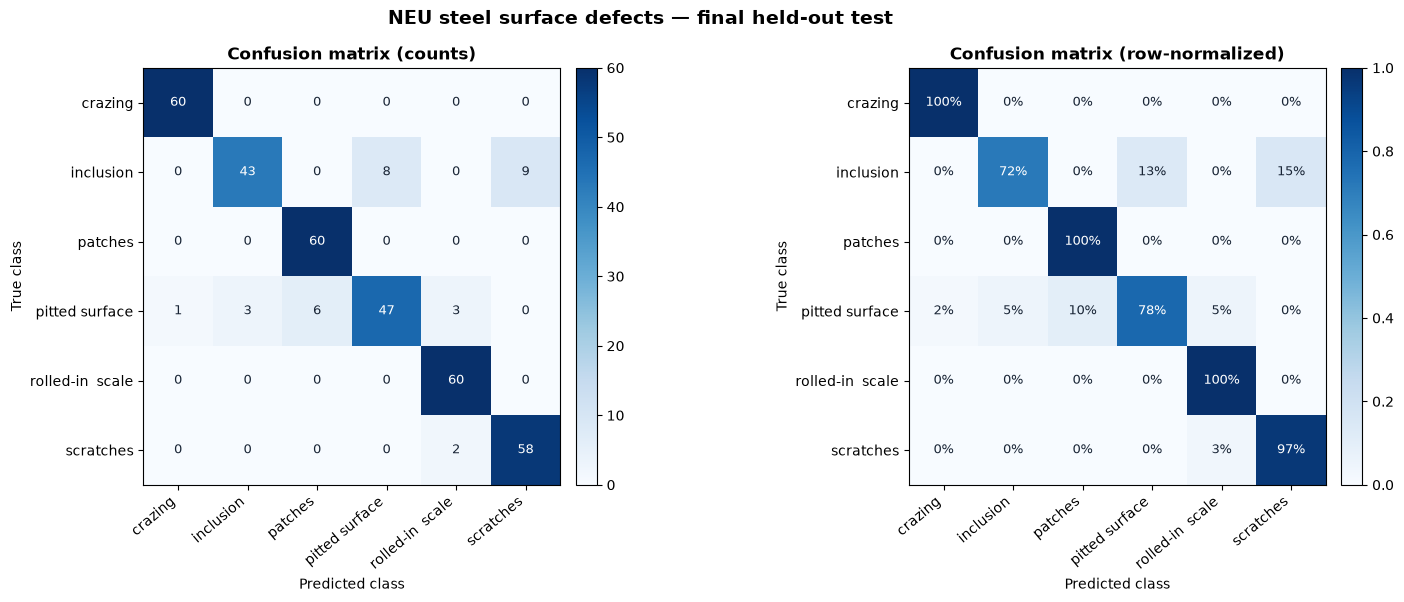

In [9]:
cm = confusion_matrix(y_test, y_pred, labels=classes)
cm_norm = cm / np.maximum(cm.sum(axis=1, keepdims=True), 1)
short_labels = [c.replace('_', ' ').replace('rolled-in', 'rolled-in ') for c in classes]
fig, axes = plt.subplots(1, 2, figsize=(15.5, 6.1))
for ax, array, title, mode in zip(axes,
    (cm, cm_norm), ('Confusion matrix (counts)', 'Confusion matrix (row-normalized)'),
    ('count', 'pct')):
    im = ax.imshow(array, cmap='Blues', vmin=0,
                   vmax=60 if mode=='count' else 1.0)
    ax.set_xticks(np.arange(len(classes)), short_labels, rotation=40, ha='right')
    ax.set_yticks(np.arange(len(classes)), short_labels)
    ax.set_xlabel('Predicted class'); ax.set_ylabel('True class')
    ax.set_title(title, weight='bold')
    for i in range(len(classes)):
        for j in range(len(classes)):
            val = array[i, j]
            label = f'{int(val)}' if mode=='count' else f'{val:.0%}'
            ax.text(j, i, label, ha='center', va='center',
                    color='white' if val > (30 if mode=='count' else .5) else '#192536',
                    fontsize=9)
    fig.colorbar(im, ax=ax, fraction=.045, pad=.025)
fig.suptitle('NEU steel surface defects — final held-out test',
             fontsize=14, fontweight='bold')
fig.tight_layout()
fig.savefig(OUT/'step5_final_confusion_matrices.png', dpi=220, bbox_inches='tight')
plt.show()

## 7. Per-class precision, recall and F1 visualization

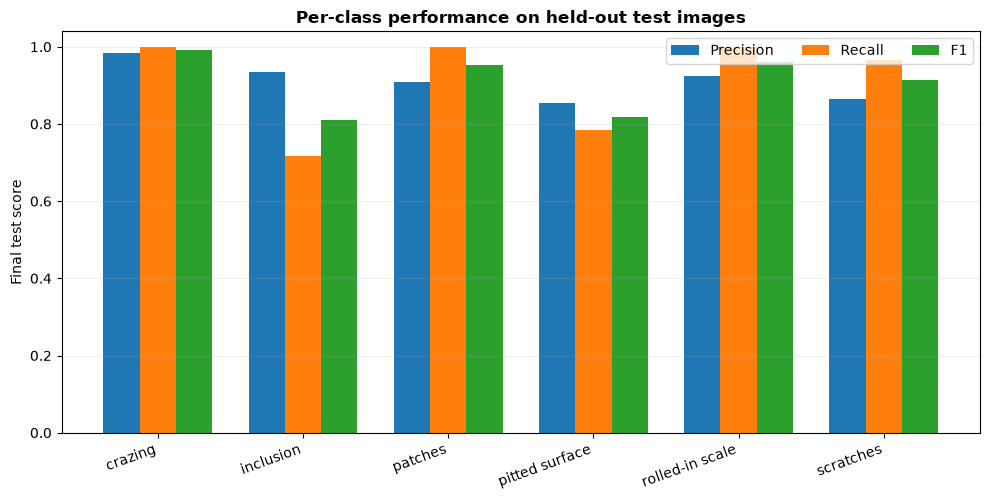

In [10]:
fig, ax = plt.subplots(figsize=(10, 5.1))
positions = np.arange(len(classes))
width = 0.25
for offset, col, title in [(-width,'precision','Precision'), (0,'recall','Recall'),
                           (width,'f1','F1')]:
    ax.bar(positions + offset, per_class[col], width=width, label=title)
ax.set_xticks(positions, [c.replace('_',' ') for c in classes], rotation=20, ha='right')
ax.set_ylim(0, 1.04)
ax.set_ylabel('Final test score')
ax.set_title('Per-class performance on held-out test images', weight='bold')
ax.grid(axis='y', alpha=.2)
ax.legend(ncol=3, loc='upper right')
fig.tight_layout()
fig.savefig(OUT/'step5_per_class_metrics.png', dpi=220, bbox_inches='tight')
plt.show()

Misclassified images: 32 / 360
Correct images: 328


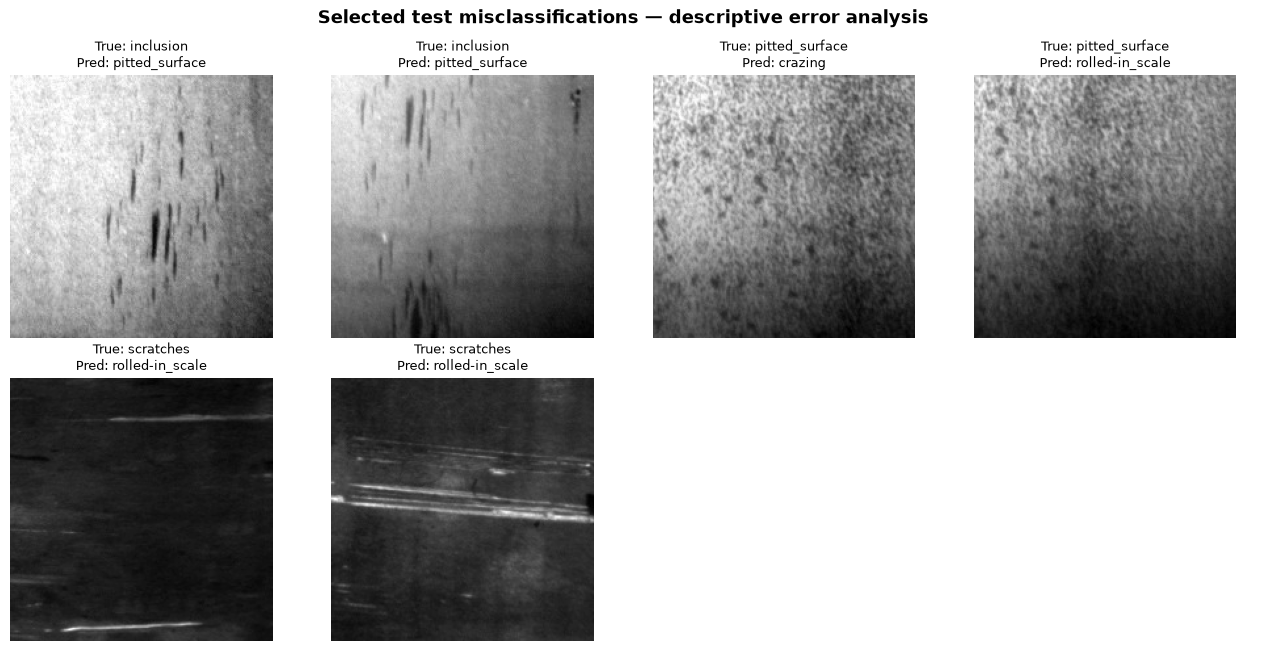

In [11]:
predictions = test_manifest[['path','label']].rename(columns={'label':'true_label'}).copy()
predictions['predicted_label'] = y_pred
predictions['correct'] = predictions['true_label'].eq(predictions['predicted_label'])
errors = predictions.loc[~predictions['correct']]
print(f'Misclassified images: {len(errors)} / {len(predictions)}')
print('Correct images:', int(predictions['correct'].sum()))
if errors.empty:
    print('No misclassifications; no error gallery is needed.')
else:
    examples = errors.groupby('true_label', sort=True, group_keys=False).head(2).head(12)
    columns = 4; rows = (len(examples) + columns - 1) // columns
    fig, axes = plt.subplots(rows, columns, figsize=(13, 3.3*rows), squeeze=False)
    for ax, (_, rec) in zip(axes.ravel(), examples.iterrows()):
        with Image.open(ROOT / rec['path']) as im:
            ax.imshow(im.convert('L'), cmap='gray')
        ax.set_title(f"True: {rec['true_label']}\nPred: {rec['predicted_label']}", fontsize=9)
        ax.axis('off')
    for ax in axes.ravel()[len(examples):]: ax.axis('off')
    fig.suptitle('Selected test misclassifications — descriptive error analysis',
                 fontsize=13, weight='bold')
    fig.tight_layout()
    fig.savefig(OUT/'step5_error_gallery.png', dpi=200, bbox_inches='tight')
    plt.show()

In [12]:
cv_table = pd.read_csv(OUT/'step4_best_per_algorithm.csv')
show = ['algorithm','config','f1_macro_mean','f1_macro_std','accuracy_mean',
        'balanced_accuracy_mean']
print('FIVE ALGORITHMS — TRAINING-ONLY CROSS-VALIDATION:')
display(cv_table[show].round(4))
print('\nSELECTED MODEL — ONE FINAL TEST:')
display(pd.DataFrame([{
    'algorithm': selection['selected_algorithm'],
    'configuration': selection['selected_configuration'],
    'CV macro-F1': selection['cv_macro_f1_mean'],
    'Held-out macro-F1': float(macro_f1),
    'Held-out accuracy': float(acc),
}]).round(4))

FIVE ALGORITHMS — TRAINING-ONLY CROSS-VALIDATION:


,algorithm,config,f1_macro_mean,f1_macro_std,accuracy_mean,balanced_accuracy_mean
0,Random Forest,trees180_leaf3,0.9416,0.0122,0.9416,0.9417
1,SVM (RBF),NoPCA_C3,0.9143,0.0105,0.9152,0.9153
2,Decision Tree,depthNone_leaf5,0.9091,0.0195,0.9090,0.9090
3,Gaussian Naive Bayes,PCA64_smooth1e-8,0.7818,0.0145,0.7860,0.7857
4,k-Nearest Neighbors,PCA64_k5_distance,0.6148,0.0229,0.6526,0.6522



SELECTED MODEL — ONE FINAL TEST:


,algorithm,configuration,CV macro-F1,Held-out macro-F1,Held-out accuracy
0,Random Forest,trees180_leaf3,0.9416,0.9077,0.9111


In [ ]:
per_class.to_csv(OUT/'step5_per_class_metrics.csv', index=False)
predictions.to_csv(OUT/'step5_final_predictions.csv', index=False)
summary.to_csv(OUT/'step5_final_summary.csv', index=False)
np.save(OUT/'step5_confusion_matrix.npy', cm)
final_result = {
    'dataset': selection['dataset'],
    'evaluation_type': 'ONE held-out final test of Step 4 CV-selected model',
    'heldout_folder_name': 'validation',
    'heldout_role': 'final test only',
    'model_selection_basis': selection['selection_metric'],
    'selected_algorithm': selection['selected_algorithm'],
    'selected_configuration': selection['selected_configuration'],
    'cv_macro_f1_mean': float(selection['cv_macro_f1_mean']),
    'cv_macro_f1_std': float(selection['cv_macro_f1_std']),
    'n_training_images_after_dedup': int(selection['train_samples']),
    'n_test_images': int(len(y_test)),
    'feature_count': int(X_test.shape[1]),
    'classes': classes,
    'metrics': {
        'accuracy': float(acc), 'balanced_accuracy': float(balanced_acc),
        'precision_macro': float(macro_p), 'recall_macro': float(macro_r),
        'f1_macro': float(macro_f1), 'f1_weighted': float(weighted_f1),
    },
    'per_class': per_class.to_dict(orient='records'),
    'confusion_matrix': cm.tolist(),
    'test_set_used_for_tuning': False,
    'retraining_after_test': False,
    'model_file': selection['model_file'],
}
marker.write_text(json.dumps(final_result, indent=2), encoding='utf-8')
print('Saved final metrics:', marker)
for name in ['step5_final_summary.csv','step5_per_class_metrics.csv',
             'step5_final_predictions.csv','step5_final_confusion_matrices.png',
             'step5_per_class_metrics.png']:
    print('  ', OUT/name)

Saved final metrics: /home/eren/base/NEU_Steel_Defects_CPU/outputs/step5_final_test_metrics.json
   /home/eren/base/NEU_Steel_Defects_CPU/outputs/step5_final_summary.csv
   /home/eren/base/NEU_Steel_Defects_CPU/outputs/step5_per_class_metrics.csv
   /home/eren/base/NEU_Steel_Defects_CPU/outputs/step5_final_predictions.csv
   /home/eren/base/NEU_Steel_Defects_CPU/outputs/step5_final_confusion_matrices.png
   /home/eren/base/NEU_Steel_Defects_CPU/outputs/step5_per_class_metrics.png
STEP 5 COMPLETE — final held-out evaluation finished. Do not retune on the test set.
